# 2 · Thermodynamics basics — from fuel to cylinder pressure

**Engine design basics — notebook 2.**

For the mechanics, thermodynamics delivers one thing: the **cylinder pressure
$p(\theta)$**. It sets the gas force on the piston, the peak load on rod and
crank, the torque and its harmonics. This notebook builds that curve from the
ground up, with the simplest model that still behaves like an engine:

1. ideal-gas compression and the Otto cycle (why compression ratio matters),
2. the energy chain air → fuel → heat → work → power,
3. a crank-angle-resolved *single-zone* model with a Wiebe heat-release law,
4. the effect of ignition timing on peak pressure and work.

**You should come out knowing** how imep, bmep and power are linked, what sets
peak pressure, and what the simple model leaves out.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import enginecalc as ec
from enginecalc import SERIES, INK, INK2, GRID, tidy
ec.use_style()

eng = ec.Engine()
comb = ec.Combustion()

## 2.1 · Ideal gas and the first law — the two equations you need

$$pV = mRT \qquad\qquad dU = \delta Q - p\,dV$$

For an ideal gas $dU = m c_v\,dT$. A process without heat exchange
(*adiabatic*, reversible) then gives $pV^\gamma = \text{const}$ with
$\gamma = c_p/c_v$. Real compression is close to that with a *polytropic*
exponent $n\approx1.32$–$1.36$ (some heat goes to the walls).

Compressing from BDC to TDC by the compression ratio
$\varepsilon = (V_d + V_c)/V_c$:

$$p_{TDC} = p_1\,\varepsilon^{\,n}\qquad T_{TDC} = T_1\,\varepsilon^{\,n-1}$$

In [2]:
eps = eng.compression_ratio
p1, T1 = comb.p_ivc, comb.T_ivc
for n in (1.30, 1.35, 1.40):
    print(f"n = {n:.2f}:  p_TDC = {p1*eps**n/1e5:5.1f} bar   T_TDC = {T1*eps**(n-1):4.0f} K")

n = 1.30:  p_TDC =  30.9 bar   T_TDC =  720 K
n = 1.35:  p_TDC =  35.2 bar   T_TDC =  821 K
n = 1.40:  p_TDC =  40.1 bar   T_TDC =  935 K


A motored (non-firing) engine already reaches ≈ 30–35 bar. Firing adds the
combustion pressure rise on top.

## 2.2 · The ideal Otto cycle

Idealise the four strokes as: adiabatic compression → heat added at constant
volume (instant combustion at TDC) → adiabatic expansion → heat rejected at
constant volume. The thermal efficiency depends only on $\varepsilon$ and $\gamma$:

$$\eta_{Otto} = 1 - \frac{1}{\varepsilon^{\gamma-1}}$$

This is the reason for high compression ratios — and knock is the reason they
stop at ≈ 12–14 for gasoline.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


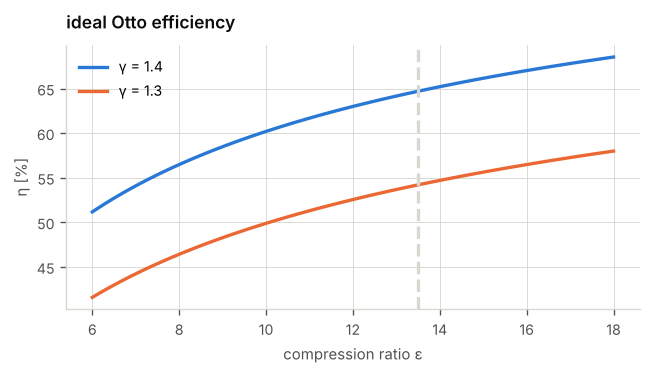

ε = 13.5:  η = 64.7 % (air, γ=1.4),  54.2 % (burnt gas, γ≈1.3)


In [3]:
e_range = np.linspace(6, 18, 100)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for g in (1.40, 1.30):
    ax.plot(e_range, ec.otto_efficiency(e_range, g) * 100, label=f"γ = {g}")
ax.axvline(eps, color=GRID, ls="--")
tidy(ax, title="ideal Otto efficiency", xlabel="compression ratio ε", ylabel="η [%]")
ax.legend(); plt.tight_layout(); plt.show()
print(f"ε = {eps}:  η = {ec.otto_efficiency(eps,1.4)*100:.1f} % (air, γ=1.4),  "
      f"{ec.otto_efficiency(eps,1.3)*100:.1f} % (burnt gas, γ≈1.3)")

Real engines reach maybe 60–70 % of the Otto value: finite burn duration, wall
heat loss, gas exchange work, real gas properties.

## 2.3 · The energy chain: air → fuel → work → power

Per cylinder and cycle:

| step | relation |
|---|---|
| trapped air | $m_a = \dfrac{p_1 V_1}{R T_1}$ (or $\lambda_a\,\rho_{a}\,V_d$ with volumetric efficiency $\lambda_a$) |
| fuel | $m_f = m_a / \text{AFR}$ (stoichiometric ≈ 14.7, full load rich ≈ 12.5–13) |
| fuel energy | $Q_f = m_f\,H_u$, $H_u \approx 43$ MJ/kg |
| indicated work | $W_i = \oint p\,dV = \eta_i\,Q_f$ |
| indicated mean effective pressure | $\text{imep} = W_i / V_d$ |

**Mean effective pressure** is the constant pressure that, acting over one
expansion stroke, would do the same work. It is the size-independent
"specific load" of an engine. Power for a four-stroke (one work cycle per
two revolutions):

$$P = \text{mep}\cdot V_{H}\cdot\frac{n}{2}\qquad T = \frac{\text{mep}\cdot V_H}{4\pi}$$

with $V_H$ the total displacement and $n$ in rev/s. The torque relation is worth
memorising: **1 bar bmep ≈ 8 N·m per litre** ($10^5\cdot10^{-3}/4\pi = 7.96$).

In [4]:
m_a = ec.trapped_mass(eng, comb)
m_f = m_a / comb.afr
Q_f = m_f * comb.lhv
print(f"trapped air    m_a = {m_a*1e6:.1f} mg")
print(f"fuel           m_f = {m_f*1e6:.2f} mg")
print(f"fuel energy    Q_f = {Q_f:.0f} J   per cylinder and cycle")
print(f"released heat  Q   = {ec.heat_per_cycle(eng, comb):.0f} J   (η_q = {comb.eta_q})")

trapped air    m_a = 299.2 mg
fuel           m_f = 23.38 mg
fuel energy    Q_f = 1005 J   per cylinder and cycle
released heat  Q   = 754 J   (η_q = 0.75)


## 2.4 · Combustion as heat release — the Wiebe function

Combustion is not instantaneous. The burned mass fraction is usually described by
the empirical **Wiebe** function, starting at $\theta_0$ with duration $\Delta\theta$:

$$x_b(\theta) = 1 - \exp\left[-a\left(\frac{\theta-\theta_0}{\Delta\theta}\right)^{m+1}\right]$$

$a = 6.9$ means 99.9 % burned at $\theta_0+\Delta\theta$; the shape factor $m\approx 2$
gives the typical S-curve. Heat is released in proportion: $dQ = Q\,dx_b$.

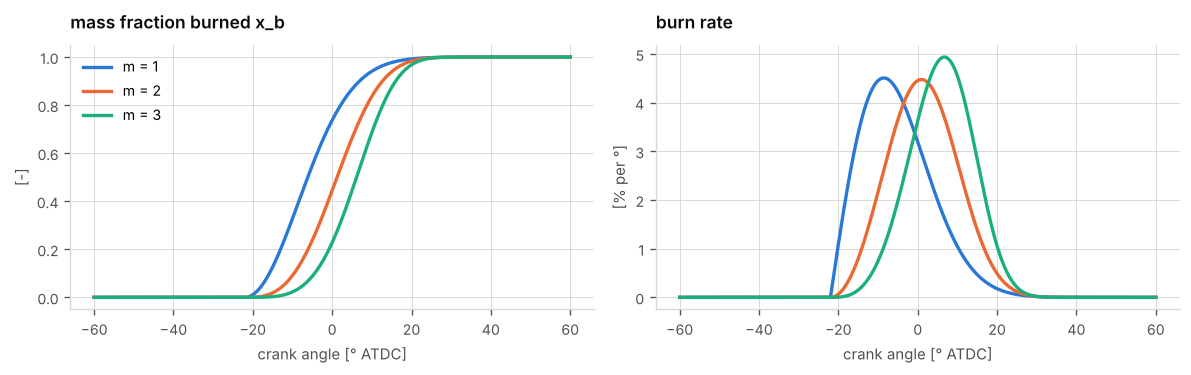

In [5]:
thd = np.linspace(-60, 60, 600)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for m in (1.0, 2.0, 3.0):
    xb, dxb = ec.wiebe(np.radians(thd), np.radians(comb.soc_deg), np.radians(comb.duration_deg), comb.wiebe_a, m)
    axs[0].plot(thd, xb, label=f"m = {m:.0f}")
    axs[1].plot(thd, np.radians(1) * dxb * 100, label=f"m = {m:.0f}")
tidy(axs[0], title="mass fraction burned x_b", xlabel="crank angle [° ATDC]", ylabel="[-]")
tidy(axs[1], title="burn rate", xlabel="crank angle [° ATDC]", ylabel="[% per °]")
axs[0].legend(); plt.tight_layout(); plt.show()

## 2.5 · The single-zone model

Treat the cylinder content as one ideal gas with constant $\gamma$, closed
between inlet-valve closing and exhaust-valve opening (here simply BDC to BDC).
Combine the first law $dU = \delta Q - p\,dV$ with $U = \frac{pV}{\gamma-1}$:

$$\frac{1}{\gamma-1}\left(V\,dp + p\,dV\right) = \delta Q - p\,dV
\quad\Rightarrow\quad
\boxed{\frac{dp}{d\theta} = \frac{\gamma-1}{V}\frac{dQ}{d\theta} - \gamma\frac{p}{V}\frac{dV}{d\theta}}$$

$V(\theta)$ and $dV/d\theta$ come straight from notebook 1. That one ODE is
the entire model (`ec.pressure_trace`). The gas-exchange strokes are set to
constant pressures with a short blend after exhaust valve opening — crude, but
their effect on the mechanics is small.

> **What is simplified:** constant $\gamma$ (real: ≈1.38 cold → ≈1.25 hot),
> wall heat loss lumped into $\eta_q$ (real: Woschni-type correlation),
> no residual gas, valve events at BDC, no blow-by. Fine for loads; not for
> combustion development.

peak pressure     110.0 bar  at 9.7° ATDC
indicated work    393 J  ->  imep = 15.71 bar
indicated eff.    39.1 %  of fuel energy (Otto γ=1.3: 54.2 %  ×  η_q 0.75)
peak gas temp.    3031 K   (overestimated, constant γ)


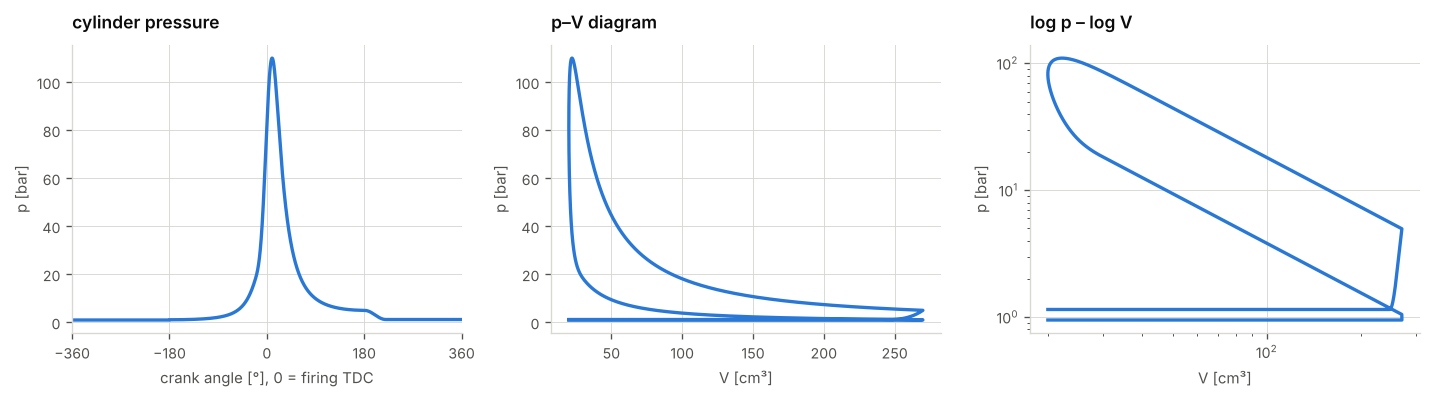

In [6]:
th, p, ex = ec.pressure_trace(eng, comb)
deg = np.degrees(th)
i_max = np.argmax(p)
print(f"peak pressure     {p[i_max]/1e5:.1f} bar  at {deg[i_max]:.1f}° ATDC")
print(f"indicated work    {ex['W_ind']:.0f} J  ->  imep = {ex['imep']/1e5:.2f} bar")
print(f"indicated eff.    {ex['W_ind']/Q_f*100:.1f} %  of fuel energy "
      f"(Otto γ=1.3: {ec.otto_efficiency(eps,1.3)*100:.1f} %  ×  η_q {comb.eta_q})")
print(f"peak gas temp.    {ex['T'].max():.0f} K   (overestimated, constant γ)")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
axs[0].plot(deg, p / 1e5)
axs[0].set_xlim(-360, 360); axs[0].set_xticks(range(-360, 361, 180))
tidy(axs[0], title="cylinder pressure", xlabel="crank angle [°], 0 = firing TDC", ylabel="p [bar]")
axs[1].plot(ex["V"] * 1e6, p / 1e5)
tidy(axs[1], title="p–V diagram", xlabel="V [cm³]", ylabel="p [bar]")
axs[2].loglog(ex["V"] * 1e6, p / 1e5)
tidy(axs[2], title="log p – log V", xlabel="V [cm³]", ylabel="p [bar]")
axs[2].xaxis.set_minor_formatter(plt.NullFormatter())
plt.tight_layout(); plt.show()

On the log-log plot, compression and late expansion are straight lines of slope
$-\gamma$: that is how pressure-trace analysts check sensor offset and
polytropic exponents on real measurements. The small loop at the bottom is the
gas-exchange (pumping) work — negative here because exhaust pressure > intake.

## 2.6 · Ignition timing — the strongest lever on peak pressure

Move the start of combustion and watch imep and $p_{max}$:

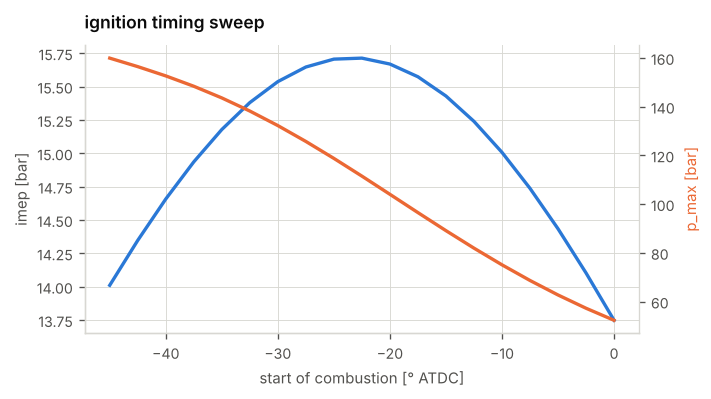

MBT (max imep) at SOC ≈ -22.5°, p_max there 111 bar, peak at 9° ATDC
10° earlier: imep 15.38 bar, p_max 138 bar


In [7]:
socs = np.arange(-45, 1, 2.5)
imep, pmax, loc = [], [], []
for s in socs:
    c = ec.Combustion(soc_deg=s)
    t_, p_, e_ = ec.pressure_trace(eng, c, n=3601)
    imep.append(e_["imep"] / 1e5); pmax.append(p_.max() / 1e5); loc.append(np.degrees(t_[p_.argmax()]))
imep, pmax = np.array(imep), np.array(pmax)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(socs, imep, label="imep [bar]")
ax2 = ax.twinx(); ax2.plot(socs, pmax, color=SERIES[1], label="p_max [bar]")
ax2.spines["right"].set_visible(True); ax2.grid(False)
tidy(ax, title="ignition timing sweep", xlabel="start of combustion [° ATDC]", ylabel="imep [bar]")
ax2.set_ylabel("p_max [bar]", color=SERIES[1])
plt.tight_layout(); plt.show()
k = np.argmax(imep)
print(f"MBT (max imep) at SOC ≈ {socs[k]:.1f}°, p_max there {pmax[k]:.0f} bar, peak at {loc[k]:.0f}° ATDC")
print(f"10° earlier: imep {imep[max(k-4,0)]:.2f} bar, p_max {pmax[max(k-4,0)]:.0f} bar")

Around the optimum (MBT, *minimum advance for best torque*) imep is flat, but peak
pressure keeps rising steeply with advance. Rule of thumb: best efficiency when
the pressure peak sits at **≈ 10–15° ATDC** and 50 % mass burned at ≈ 8–10° ATDC.
For the mechanical designer this means: **the design peak pressure is set by the
calibration (and its scatter, knock, cycle-to-cycle variation), not by the
torque.** Load cases usually take a $p_{max}$ with margin above the nominal value.

## 2.7 · From imep to brake power

Brake (shaft) output = indicated − friction:
$\text{bmep} = \text{imep} - \text{fmep}$. Friction rises strongly with speed. A
common correlation form (Chen–Flynn) is

$$\text{fmep} = C + A\,p_{max} + B\,c_m + Q\,c_m^2$$

The constants below are *illustrative* only, picked to give ≈ 2–3 bar at top
speed, which is plausible for a race engine.

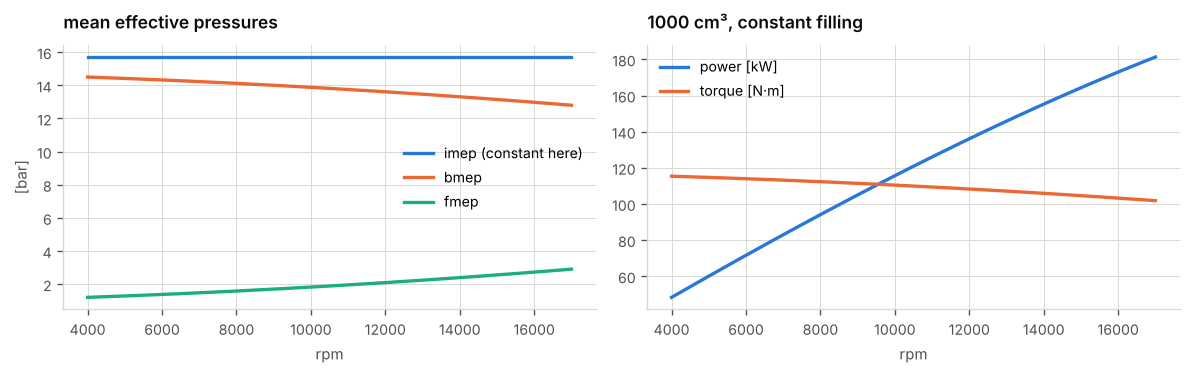

@15000 rpm: bmep 13.2 bar, P = 164 kW (223 PS), T = 105 N·m


In [8]:
C, A, B, Q = 0.4, 0.005, 0.03, 0.0015      # bar, -, bar/(m/s), bar/(m/s)^2  (illustrative)
rpm = np.linspace(4000, 17000, 200)
cm = 2 * eng.stroke * rpm / 60
imep0 = ex["imep"] / 1e5
pmax0 = p.max() / 1e5
fmep = C + A * pmax0 + B * cm + Q * cm**2
bmep = imep0 - fmep
V_H = eng.V_d * eng.n_cyl
P = bmep * 1e5 * V_H * rpm / 60 / 2 / 1e3
T = bmep * 1e5 * V_H / (4 * np.pi)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(rpm, np.full_like(rpm, imep0), label="imep (constant here)")
axs[0].plot(rpm, bmep, label="bmep"); axs[0].plot(rpm, fmep, label="fmep")
tidy(axs[0], title="mean effective pressures", xlabel="rpm", ylabel="[bar]"); axs[0].legend()
axs[1].plot(rpm, P, label="power [kW]"); axs[1].plot(rpm, T, label="torque [N·m]")
tidy(axs[1], title=f"{V_H*1e6:.0f} cm³, constant filling", xlabel="rpm"); axs[1].legend()
plt.tight_layout(); plt.show()
i = np.argmin(abs(rpm - 15000))
print(f"@15000 rpm: bmep {bmep[i]:.1f} bar, P = {P[i]:.0f} kW ({P[i]*1.36:.0f} PS), T = {T[i]:.0f} N·m")

With constant filling, power just keeps climbing until friction wins. Real
torque curves are shaped mainly by the **volumetric efficiency** — intake and
exhaust tuning, valve timing — which a later notebook can add as $\lambda_a(n)$.

## 2.8 · Take-aways

- $p\,V^\gamma$ compression already gives ≈ 30+ bar at TDC for ε ≈ 13.5; firing adds the rest.
- $\eta_{Otto} = 1-\varepsilon^{1-\gamma}$ sets the ceiling; real indicated efficiency is ≈ 35–42 %.
- mep is the specific load: $P = \text{mep}\,V_H\,n/2$, and 1 bar bmep ≈ 8 N·m/l.
- The single-zone ODE $dp/d\theta = \frac{\gamma-1}{V}\dot Q - \gamma\frac{p}{V}\dot V$ with a Wiebe law is enough to generate realistic load cases.
- $p_{max}$ depends steeply on spark timing; design to a $p_{max}$ with margin.

**Exercises**

1. Raise $\varepsilon$ to 14.5 (`ec.Engine(compression_ratio=14.5)`). How do imep and $p_{max}$ change?
2. Halve the burn duration. Compare $p_{max}$ and imep — what does "fast burn" buy, and what does it cost the crank?
3. Replace constant filling by a volumetric efficiency curve $\lambda_a(n)$ peaking at 1.1 near 12 500 rpm (scale `p_ivc` with it) and redo the power curve.

**Next:** notebook 3 — gas force plus inertia force, all the way to the torque on the crankshaft.